<a href="https://colab.research.google.com/github/amyylxn/Ontario-Price-Forecasting/blob/main/price_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
   from google.colab import drive
   drive.mount('/content/drive')

   DATA_DIR = '/content/drive/MyDrive/ontario_data'

Mounted at /content/drive


In [2]:
   import os
   for root, dirs, files in os.walk(DATA_DIR):
       for f in files:
           print(os.path.join(root, f))

/content/drive/MyDrive/ontario_data/ieso/PUB_PriceHOEPPredispOR_2022.csv


In [3]:
   path = f'{DATA_DIR}/ieso/PUB_PriceHOEPPredispOR_2022.csv'
   with open(path) as f:
       for _ in range(8):
           print(f.readline().rstrip())

\\Yearly HOEP OR Predispatch Report,,,,,,,,
\\Created at 2023-01-31 08:02:23,,,,,,,,
\\For 2022,,,,,,,,
Date,Hour,HOEP,Hour 1 Predispatch,Hour 2 Predispatch,Hour 3 Predispatch,OR 10 Min Sync,OR 10 Min non-sync,OR 30 Min
2022-01-01,1,32.18,27.75,27.73,32.41,1.19,0.20,0.20
2022-01-01,2,59.04,23.23,28.62,32.41,1.30,0.20,0.20
2022-01-01,3,18.79,17.00,14.36,29.13,1.21,0.20,0.20
2022-01-01,4,15.78,18.00,17.20,14.39,1.22,0.20,0.20


In [4]:
   import pandas as pd

   df = pd.read_csv(path, skiprows=3)
   print(df.shape)
   df.head()

(8760, 9)


,Date,Hour,HOEP,Hour 1 Predispatch,Hour 2 Predispatch,Hour 3 Predispatch,OR 10 Min Sync,OR 10 Min non-sync,OR 30 Min
0,2022-01-01,1,32.18,27.75,27.73,32.41,1.19,0.2,0.2
1,2022-01-01,2,59.04,23.23,28.62,32.41,1.30,0.2,0.2
2,2022-01-01,3,18.79,17.00,14.36,29.13,1.21,0.2,0.2
3,2022-01-01,4,15.78,18.00,17.20,14.39,1.22,0.2,0.2
4,2022-01-01,5,0.41,12.99,12.99,29.51,1.23,0.2,0.2


In [5]:
df.info()
print(df['HOEP'].describe())
print(df.isna().sum())
print(df.duplicated(subset=['Date', 'Hour']).sum(), "duplicate hours")
print(df['Date'].min(), df['Date'].max())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                8760 non-null   object 
 1   Hour                8760 non-null   int64  
 2   HOEP                8760 non-null   float64
 3   Hour 1 Predispatch  8744 non-null   float64
 4   Hour 2 Predispatch  8744 non-null   float64
 5   Hour 3 Predispatch  8744 non-null   float64
 6   OR 10 Min Sync      8760 non-null   float64
 7   OR 10 Min non-sync  8760 non-null   float64
 8   OR 30 Min           8760 non-null   float64
dtypes: float64(7), int64(1), object(1)
memory usage: 616.1+ KB
count    8760.000000
mean       44.957614
std        36.953743
min        -4.430000
25%        14.370000
50%        44.560000
75%        62.420000
max       689.330000
Name: HOEP, dtype: float64
Date                   0
Hour                   0
HOEP                   0
Hour 1 Predispatch   

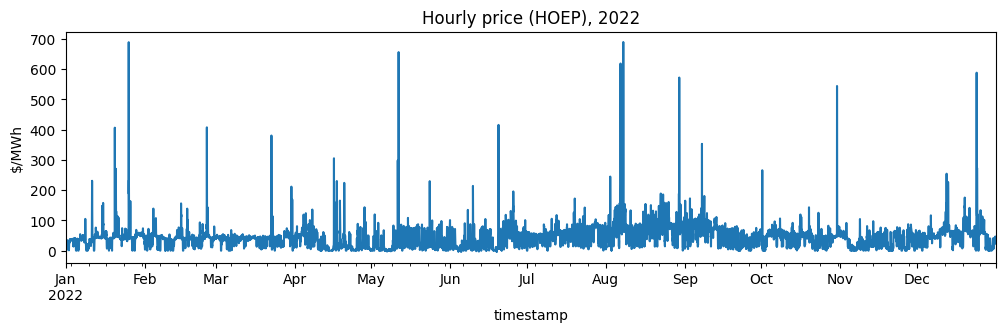

In [6]:
import matplotlib.pyplot as plt

df['Date'] = pd.to_datetime(df['Date'])
# Hour 1 = the hour ending at 1:00, so it starts at 0:00
df['timestamp'] = df['Date'] + pd.to_timedelta(df['Hour'] - 1, unit='h')

df.set_index('timestamp')['HOEP'].plot(figsize=(12, 3), title='Hourly price (HOEP), 2022')
plt.ylabel('$/MWh')
plt.show()